In [5]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan

import sys 
sys.path.append('../Code/')
import modules as mod



In [6]:
def plot_rectangle_module(M): 
    ## add coordinates of corners!!
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ## rectangles 
    list_rectanlges = M.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)

    plt.xlim([-3, 15])
    plt.ylim([-3, 15])

    plt.title('Rectangle module')  
    plt.show()
    
def plot_rectangle_modules(M,N): 
    ## add coordinates of corners!!
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ## rectangles 
    list_rectanlges = M.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)
    list_rectanlges = N.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)

    plt.xlim([-3, 15])
    plt.ylim([-3, 15])

    plt.title('Rectangle module')  
    plt.show()
    
def closure_lub(Points): 
        """ Find the closure under least upper boud of the critical points"""
        ## Todo: check that it works properly on an example
        ## Not the most efficient way to code this function 
    
        l = len(Points)
        for i in range(l): 
            p = Points[i]
            for j in range(i+1, l): 
                q = Points[j]
                if not mod.are_comparable(p,q):
                    lub = (max(p[0],q[0]), max(p[1],q[1]))
                    Points.append(lub)

        return list(set(Points))
    
def plot_weighted_bottleneck(M,N, filename = 'weightedBottlneckDistance'): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    print('Maximum distance for lines:')
    print(max(DD))
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-5,5,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    print('Maximum distance computed:')
    print(max(Dist))     
    plt.figure(figsize=(8,8))
    plt.scatter(T, BB, c= Dist,s = 10, cmap = "summer")
    plt.scatter(T[idx], BB[idx], marker = 'x', color = 'red')
    print(T[idx])
    print(BB[idx])
    
    ## plot markers for the lines through critical points
    b_crit = []
    theta_crit = []
    for j in range(len(Lines)):
        Line = Lines[j]
        b= Line.b[0]
        theta = atan(Line.m[1]/Line.m[0])
        b_crit.append(b)
        theta_crit.append(theta)
    
    for j in range(len(Lines)): 
        plt.scatter(theta_crit[j], b_crit[j], marker = 'x', color = 'grey')
        #plt.text(theta_crit[j], b_crit[j], str(Crit[j]))
    val = max(DD)
    idx=DD.index(val)
    plt.scatter(theta_crit[idx], b_crit[idx], marker = 'x', color = 'black')
    ## plot titles
    plt.xlabel('theta')
    plt.ylabel('b')
    plt.title("Weighted bottleneck distance as a function of theta and b")
    plt.colorbar(label="Weighted distance", orientation="horizontal")
    plt.clim(0,max(Dist))
    plt.savefig(filename)
    plt.show()
    
def compute_weighted_bottleneck_distances(M,N): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    print('Maximum distance for lines:')
    print(max(DD))
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-5,5,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    print('Maximum distance computed:')
    print(max(Dist))     
    print(T[idx])
    print(BB[idx])
    
    s = sin(T[idx])
    c = cos(T[idx])
    maxm = max(s,c)
    L_max = mod.Line((c/maxm, s/maxm), (BB[idx],-BB[idx]))
    return T,BB, idx, L_max




In [7]:
rect_m1 = mod.Rectangle((0,0),(7,7),1)
rect_m2 = mod.Rectangle((0,4),(7,11),1)
M = mod.RectangleModule([rect_m1,rect_m2])
rect_n1 = mod.Rectangle((0,0),(7,11),1)
rect_n2 = mod.Rectangle((0,4),(7,7),1)
N= mod.RectangleModule([rect_n1,rect_n2])

In [8]:
T, BB, idx, L_max = compute_weighted_bottleneck_distances(M,N)

There are 5 lines through critical points
Maximum distance for lines:
2.5454545454545454
Maximum distance computed:
2.4876812330587637
0.9995976625058433
-0.050505050505050164


In [9]:
print(L_max.m)
print(L_max.b)

(0.6426609771683313, 1.0)
(-0.050505050505050164, 0.050505050505050164)


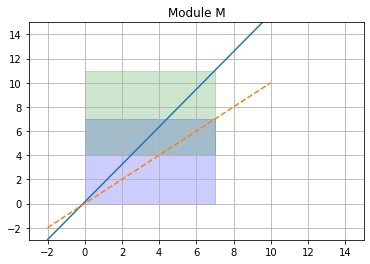

In [10]:
fig = plt.figure()
ax = fig.add_subplot(111)
plt.grid(visible = True )
## rectangles 
a1 = rect_m1.bottom_left 
h1= rect_m1.top_right[0]- a1[0]
v1= rect_m1.top_right[1]- a1[1]
a2 = rect_m2.bottom_left 
h2= rect_m2.top_right[0]- a2[0]
v2= rect_m2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)

b1 = L_max.b[0]
b2 = L_max.b[1]
m1 = L_max.m[0]
m2 = L_max.m[1]
plt.plot(x, m2*(x-b1)/m1 +b2, linestyle='solid') ##L _
plt.plot(x,x,linestyle='dashed')

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])

plt.title('Module M')  
#plt.savefig('moduleM')
plt.show()

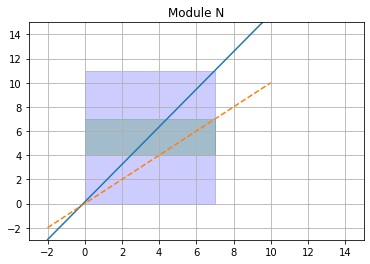

In [11]:
fig = plt.figure()
ax = fig.add_subplot(111)
plt.grid(visible = True )
## rectangles 
a1 = rect_n1.bottom_left 
h1= rect_n1.top_right[0]- a1[0]
v1= rect_n1.top_right[1]- a1[1]
a2 = rect_n2.bottom_left 
h2= rect_n2.top_right[0]- a2[0]
v2= rect_n2.top_right[1]- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-2, 10, 1000)

b1 = L_max.b[0]
b2 = L_max.b[1]
m1 = L_max.m[0]
m2 = L_max.m[1]
plt.plot(x, m2*(x-b1)/m1 +b2, linestyle='solid') ##L _
plt.plot(x,x,linestyle='dashed')

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-3, 15])
plt.ylim([-3, 15])

plt.title('Module N')  
#plt.savefig('moduleN')
plt.show()



There are 5 lines through critical points
Maximum distance for lines:
2.5454545454545454
Maximum distance computed:
2.4876812330587637
0.9995976625058433
-0.050505050505050164


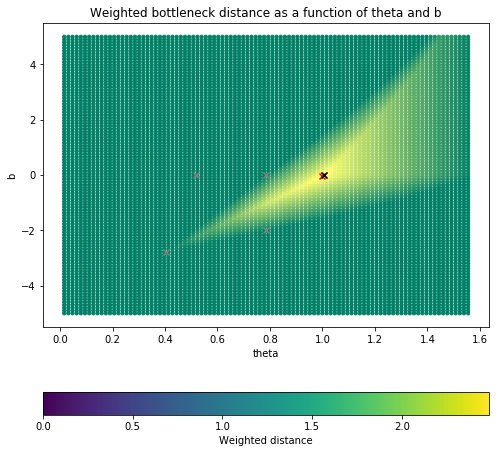

In [12]:
plot_weighted_bottleneck(M,N, 'example1-1')



### Claim 2
* for any line $L$ of the shape $L: y= x+ q$, with $1<q<4$ we have $d_B(M^L,N^L)\leq 2$,
* the value $2$ is attaained by line with $q= 2.5$

In [13]:
D = []
for q in np.linspace(1.1,3.9, 100):
    Line = mod.Line((1,1),(0,q))
    D.append(mod.compute_weighted_bottleneck(M,N,Line))
print(max(D))


1.9949494949494948


In [14]:
print(Line.m)
print(Line.b)

(1, 1)
(-1.95, 1.95)


In [16]:
L_max = mod.Line((1,1),(0,2))
mod.compute_weighted_bottleneck(M,N,L_max)

2.0

### Claim 3

In [18]:
L2 = mod.line_through_2points((0,0),(7,11))
L2.m

(0.6363636363636364, 1.0)

In [20]:
7/11

0.6363636363636364

In [19]:
d = mod.compute_bottleneck(M,N,L2)
print(d)

4.0


In [14]:
dd = mod.compute_weighted_bottleneck(M,N,L2)
print(dd)

2.0999999999999996


In [15]:
21/11

1.9090909090909092

In [16]:
0.7*3

2.0999999999999996

### Claim 4
The only line trhough critical pts that has non zero bottleneck distance is the one through $(0,0), (7,11)$ and has weigted cost $\frac{21}{11}$

In [17]:
L = mod.line_through_2points((0,0),(7,11))
d = mod.compute_weighted_bottleneck(M,N,L)
print(d)

1.9090909090909092


In [19]:
21/11

1.9090909090909092